# Iris Dataset Classification: Logistic Regression vs Decision Tree

**Objective:** Train and compare two supervised classification models using an 80/20 train-test split, feature scaling, classification metrics, and a confusion matrix heatmap.

### Steps
1. Load the Iris dataset.
2. Split the data into 80% training and 20% testing sets.
3. Standardize features using `StandardScaler` (fit on training data only).
4. Train Logistic Regression and Decision Tree classifiers.
5. Compare accuracy, precision, recall, F1-score, classification reports, and confusion matrices.


In [2]:
# If needed, uncomment and run this line to install dependencies:
# %pip install scikit-learn matplotlib seaborn pandas

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


## 1. Load and inspect the dataset

The Iris dataset contains four flower measurements and three species classes.

In [3]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="target")
class_names = iris.target_names

display(X.head())
print("Dataset shape:", X.shape)
print("Class names:", list(class_names))
print("\nClass counts:")
print(y.map(lambda label: class_names[label]).value_counts())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dataset shape: (150, 4)
Class names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Class counts:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 2. Split into training and testing sets

`test_size=0.2` reserves 20% of the records for testing. `stratify=y` preserves the class proportions in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Testing samples:  {len(X_test)} ({len(X_test) / len(X):.0%})")


Training samples: 120 (80%)
Testing samples:  30 (20%)


## 3. Train models and evaluate them

A scikit-learn `Pipeline` ensures scaling is learned from the training data only. Scaling is important for Logistic Regression; Decision Tree does not generally require it, but both models are evaluated using the same workflow for comparison.

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=42)),
    ]),
}

results = []
predictions = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


## 4. Classification reports

The classification report shows precision, recall, F1-score, and support for each Iris species, plus macro and weighted averages.

In [6]:
for name, y_pred in predictions.items():
    print(f"\n{'=' * 65}\n{name}\n{'=' * 65}")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0,
    ))



Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 5. Confusion matrix heatmaps

Rows represent the actual class and columns represent the predicted class. Values on the diagonal are correct predictions; off-diagonal values are misclassifications.

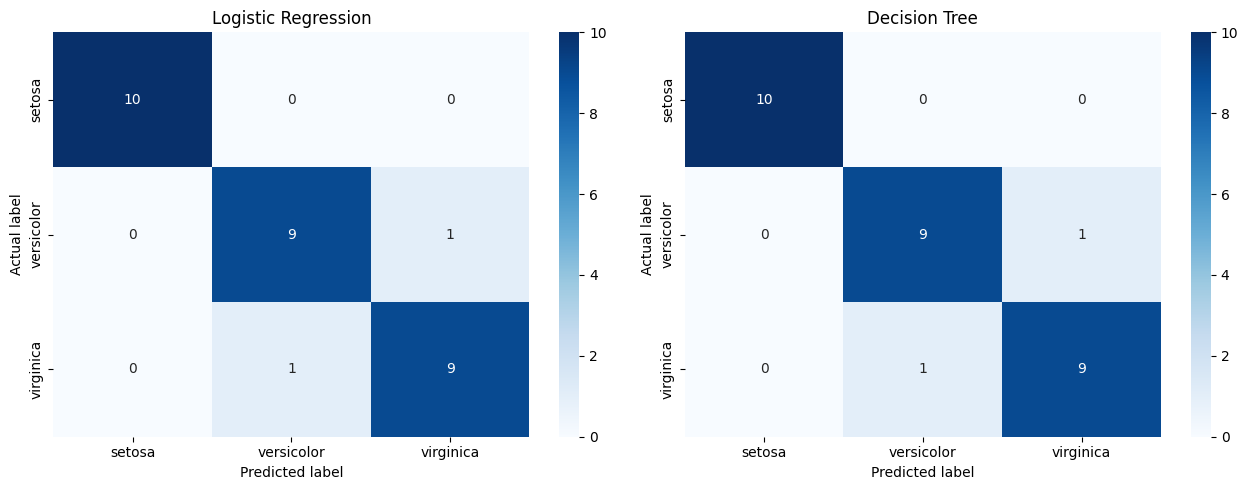

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()


## 6. Compare and conclude

Use the metric table and heatmaps to compare the models. Higher values for accuracy, precision, recall, and F1-score generally indicate better performance on this test set. For a multiclass dataset, the table uses **weighted averages** so that each class contributes according to its number of test examples.

**Conclusion template:** Based on the test-set results above, the model with the stronger overall metrics performed better on this split. The confusion matrices help identify which flower species, if any, were misclassified. Results can vary with the split and model settings.